<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/3c_modelo_lenguaje_red_recurrente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo de lenguaje con red recurrente básica
Un modelo de lenguaje asigna una probabilidad a cada secuencia $x^{[1]}, \ldots, x^{[T]}$, donde $x^{[t]} \in \mathcal{V}$ y $\mathcal{V}$ es un vocabulario de _tokens_ (palabras, subpalabras o caracteres)
$$
P(x^{[1]}, \ldots, x^{[T]}) = P(x^{[1]})\cdot \prod_{t=2}^T P(x^{[t]} \mid x^{[1]}, \ldots, x^{[t-1]})
$$
      
En esta libreta definiremos una red recurrente básica y la entrenaremos mediante descenso por gradiente estocástico para obtener un modelo de lenguaje sencillo que prediga cada _token_ a partir de los _tokens_ anteriores. Un modelo de lenguaje produce a la salida una distribución sobre todo el vocabulario $\mathcal{V}$. Con este modelo podemos generar texto eligiendo un _token_ de esa distribución y repitiendo el proceso.

El cálculo de los gradientes lo realizaremos mediante el algoritmo de retropropagación en el tiempo usando únicamente tensores de PyTorch (sin diferenciación automática).

In [1]:
from math import sqrt

import numpy as np
import matplotlib.pyplot as plt

import torch as th
from torch.nn import functional as F

import urllib.request
import re

DC = th.device("cuda" if th.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {DC}")

th.manual_seed(42)

Usando dispositivo: cuda


## Extracción de datos
Entrenaremos nuestro modelo con un texto del Proyecto Gutenberg, el cual podemos descargar usando el módulo `request` de la biblioteca `urllib`.

Específicamente, abrimos la URL con la función `urlopen`, la cual devuelve una instancia de la clase `HTTPResponse`. Con el método `read()` de esta instancia leemos el contenido y lo decodificamos a UTF-8 con el método `decode("utf-8")`.

El Proyecto Gutenberg agrega un encabezado y un pie a todos sus textos, los cuales quitamos tomando el inicio después de la línea que empieza con `*** START` y el fin antes de la línea que empieza con `*** END`.


In [2]:
def descarga_texto(URL):
  texto = urllib.request.urlopen(URL).read().decode("utf-8")

  # Quitamos el encabezado y el pie del Proyecto Gutenberg
  ini = texto.find("\n", texto.find("*** START"))
  fin = texto.find("*** END")
  texto = texto[ini + 1:fin]

  # Eliminamos caracteres especiales de salto de línea
  texto = texto.replace("\r", "")
  texto = re.sub(r"\n{3,}", "\n\n", texto).strip()

  return texto

Descargamos el libro de _Don Quijote de la Mancha_.

In [3]:
URL = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"

texto = descarga_texto(URL)

print(texto[:1000])

El ingenioso hidalgo don Quijote de la Mancha

por Miguel de Cervantes Saavedra

El ingenioso hidalgo don Quijote de la Mancha

  
Tasa

  
Testimonio de las erratas

  
El Rey

  
Al Duque de Béjar

  
Prólogo

  
Al libro de don Quijote de la Mancha

Que trata de la condición y ejercicio del famoso
hidalgo don Quijote de la Mancha

Que trata de la primera salida que de su tierra hizo
el ingenioso don Quijote

Donde se cuenta la graciosa manera que tuvo don
Quijote en armarse caballero

De lo que le sucedió a nuestro caballero cuando salió
de la venta

Donde se prosigue la narración de la desgracia de
nuestro caballero

Del donoso y grande escrutinio que el cura y el
barbero hicieron en la librería de nuestro ingenioso hidalgo

De la segunda salida de nuestro buen caballero don
Quijote de la Mancha

Del buen suceso que el valeroso don Quijote tuvo en
la espantable y jamás imaginada aventura de los molinos de viento, con
otros sucesos dignos de felice recordación

Donde se concluye y d

Construimos el vocabulario $\mathcal{V}$ y convertimos el texto a un tensor de índices.

In [4]:
# Obtenemos todos los caracteres que ocurren en el texto
# y los ordenamos alfabéticamente
vocab = sorted(set(texto))
tam_vocab = len(vocab)

# Construimos diccionarios de carácter a índice y viceversa
c2i = {c: i for i, c in enumerate(vocab)}
i2c = {i: c for i, c in enumerate(vocab)}

# Convertimos texto de una cadena de caracteres a un tensor de índices
datos = th.tensor([c2i[c] for c in texto], device=DC)

print(f"Tamaño del vocabulario: {tam_vocab}")
print(f"Tamaño del tensor de índices: {len(datos)}")
print(f"Tensor de índices: {datos}")
print(f"Caracteres del vocabulario: {vocab}")
print(f"Diccionario carácter a índice: {c2i}")
print(f"Diccionario índice a carácter: {i2c}")

Tamaño del vocabulario: 92
Tamaño del tensor de índices: 2110329
Tensor de índices: tensor([25, 57,  1,  ..., 26, 55, 59], device='cuda:0')
Caracteres del vocabulario: ['\n', ' ', '!', '"', "'", '(', ')', ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', ']', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'x', 'y', 'z', '¡', '«', '»', '¿', 'Á', 'É', 'Í', 'Ñ', 'Ó', 'Ú', 'à', 'á', 'é', 'í', 'ï', 'ñ', 'ó', 'ù', 'ú', 'ü', '—']
Diccionario carácter a índice: {'\n': 0, ' ': 1, '!': 2, '"': 3, "'": 4, '(': 5, ')': 6, ',': 7, '-': 8, '.': 9, '0': 10, '1': 11, '2': 12, '3': 13, '4': 14, '5': 15, '6': 16, '7': 17, ':': 18, ';': 19, '?': 20, 'A': 21, 'B': 22, 'C': 23, 'D': 24, 'E': 25, 'F': 26, 'G': 27, 'H': 28, 'I': 29, 'J': 30, 'L': 31, 'M': 32, 'N': 33, 'O': 34, 'P': 35, 'Q': 36, 'R': 37, 'S': 

Dado que el texto no es muy largo, convertimos todo el tensor de índices a un tensor de vectores 1-de-K para reducir el tiempo de carga.

In [5]:
datos = F.one_hot(datos, tam_vocab).float()
print(f"Tamaño del tensor de vectores 1-de-K: {datos.shape}")

Tamaño del tensor de vectores 1-de-K: torch.Size([2110329, 92])


## Red recurrente
Una red recurrente contiene celdas recurrentes junto con otras capas. La salida de una celda alimenta otras capas o celdas.

### Celda recurrente

Una celda recurrente básica consiste en una capa densa que se retroalimenta. Al procesar una secuencia, la celda recurrente básica tiene como entrada en el tiempo $t$:
* Entrada actual $\mathbf{x}^{[t]}$
* Estado anterior $\mathbf{h}^{[t - 1]}$

Para el tiempo $t$, la salida de esta capa es el estado $\mathbf{h}^{[t]}$, el cual se obtiene como:

$$
\begin{align*}
  \mathbf{h}^{[t]} & = \tanh\left(\mathbf{W}_{hh}\cdot \mathbf{h}^{[t-1]} + \mathbf{W}_{xh}\cdot \mathbf{x}^{[t]} + \mathbf{b}_h\right)\\
\end{align*}
$$



In [6]:
class CeldaRecurrente:
  def __init__(self,
               d_ent: int,
               d_edo: int,
               disp: str = 'cpu') -> None:
    self.input_size = d_ent
    self.hidden_size = d_edo
    self.disp = disp

    k = sqrt(1 / d_edo)
    self.Wxh = th.empty(d_edo, d_ent, device=disp).uniform_(-k, k)
    self.Whh = th.empty(d_edo, d_edo, device=disp).uniform_(-k, k)
    self.bh = th.zeros((d_edo), device=disp)

  def __call__(self,
               x: th.Tensor,
               h: th.Tensor) -> th.Tensor:
    h = th.tanh(self.Whh @ h + self.Wxh @ x + self.bh)
    return h

  def to(self,
         disp: str) -> None:
    self.Wxh = self.Wxh.to(disp)
    self.Whh = self.Whh.to(disp)
    self.bh = self.bh.to(disp)
    self.disp = disp

### Capa de salida
Para el modelo de lenguaje, requerimos una capa densa a la salida que tome como entrada el estado $\mathbf{h}^{[t]}$ y produzca los _logits_ $\mathbf{o}^{[t]}$.

$$
  \begin{align*}
    \mathbf{o}^{[t]} & = \mathbf{W}_{y}\mathbf{h}^{[t]} + \mathbf{b}_y
  \end{align*}
$$

In [7]:
class CapaDensa:
  def __init__(self,
               d_ent: int,
               d_sal: int,
               disp: str = "cpu") -> None:
    self.d_ent = d_ent
    self.d_sal = d_sal
    self.disp = disp

    k = sqrt(1 / d_ent)
    self.Wy = th.empty(d_sal, d_ent, device=disp).uniform_(-k, k)
    self.by = th.zeros(d_sal, device=disp)

  def __call__(self,
               x: th.Tensor) -> th.Tensor:
    return self.Wy @ x + self.by

  def to(self,
         disp: str) -> None:
    self.Wy = self.Wy.to(disp)
    self.by = self.by.to(disp)
    self.disp = disp

### Clase del modelo de lenguaje
Envolvemos el modelo de lenguaje en la clase `ModeloLenguaje`, la cual contiene la celda recurrente básica y la capa densa de salida. El método `__call__` (operador `()`) de esta clase recibe como argumentos la secuencia de entrada $\mathbf{x}^{[1]}, \ldots, \mathbf{x}^{[T]}$ y un estado inicial $\mathbf{h}^{[0]}$ y procesa la secuencia con la celda recurrente pasando cada estado oculto $\mathbf{h}^{[t]}$ por la capa de salida para obtener los _logits_ correspondientes $\mathbf{o}^{[t]}$. Para elegir el siguiente _token_ durante el entrenamiento, tomamos la siguiente entrada (_teacher forcing_).

Adicionalmente, `ModeloLenguaje` implementa el método `genera` para generar texto. El procedimiento general es el siguiente:
  * Inicializamos $x^{[1]}$ con el índice del carácter deseado y $\mathbf{h}^{[0]} = \mathbf{0}$
  * Para $t = 1, 2, \ldots$
    * Calculamos $\mathbf{h}^{[t]}$ y $\mathbf{o}^{[t]}$.
    * Muestreamos $x^{[t+1]} \sim \operatorname{softmax}\left( \mathbf{o}^{[t]} / \tau \right)$, donde $\tau \in \mathbb{R^+}$ es la temperatura, la cual divide los _logits_ antes de pasar por la función $\operatorname{softmax}$. Valores de $\tau < 1$ concentran la distribución, mientras que valores de $\tau > 1$ la aplanan.
    * Tomamos $x^{[t+1]}$ como entrada del siguiente paso.
  * Terminamos al alcanzar una longitud máxima.

In [8]:
class ModeloLenguaje:
  def __init__(self,
               d_vocab: int,
               d_edo: int,
               i2c: dict,
               c2i: dict,
               disp: str = "cpu") -> None:
    self.d_vocab = d_vocab
    self.d_edo = d_edo
    self.disp = disp
    self.i2c = i2c
    self.c2i = c2i

    self.celda = CeldaRecurrente(d_vocab, d_edo, disp=disp)
    self.salida = CapaDensa(d_edo, d_vocab, disp=disp)

  def __call__(self,
               x: th.Tensor,
               h0: th.Tensor) -> tuple[th.Tensor, th.Tensor]:
    h = h0

    estados = []
    logits = []

    for t in range(x.shape[0]):
      h = self.celda(x[t], h)
      l = self.salida(h)

      estados.append(h)
      logits.append(l)

    estados = th.stack(estados)
    logits = th.stack(logits)

    return estados, logits

  def genera(self,
             h: th.Tensor,
             idx_inicial: int,
             tamgen: int = 300,
             temp: float = 1.0) -> str:
    idx = idx_inicial

    texto_gen = []
    with th.no_grad():
      # Generamos carácter por carácter
      for _ in range(tamgen):
        # Convertimos el índice actual a su representación
        # 1-de-K
        x = F.one_hot(th.tensor([idx], device=self.disp), self.d_vocab).float()

        # Pasamos el vector 1-de-K a la celda
        estados, logits = self(x, h)
        h = estados[-1]

        # Los logits pasan por la softmax
        p = F.softmax(logits[-1] / temp, dim=-1)

        # Muestreamos el índice del siguiente carácter a partir de la
        # distribución categórica de la predicción de softmax
        idx = th.multinomial(p, 1).item()

        # Convierte el índice en su carácter y lo agrega a la lista de
        # caracteres generados
        texto_gen.append(self.i2c[idx])

    return "".join(texto_gen)

  def to(self,
         disp: str) -> None:
    self.celda.to(disp)
    self.salida.to(disp)
    self.disp = disp

## Funciones de entrenamiento
Para entrenar el modelo de lenguaje usaremos la función de pérdida de entropía cruzada. En particular, buscaremos minimizar el promedio de las pérdidas de todos los elementos de la secuencia de longitud $T$:

$$
\mathcal{L} = \frac{1}{T}\sum_{t=1}^{T}\mathrm{L}^{[t]}
$$

donde $\mathrm{L}^{[t]} = \mathrm{L}\left(\hat{\mathbf{y}}^{[t]}, \mathbf{y}^{[t]}\right)$ es la entropía cruzada evaluada con la predicción $\hat{\mathbf{y}}^{[t]} = \operatorname{softmax}(\mathbf{o}^{[t]})$ y el vector 1-de-K $\mathbf{y}^{[t]} = \mathbf{x}^{[t+1]}$ del siguiente _token_:
$$
\mathrm{L}\left(\hat{\mathbf{y}}^{[t]}, \mathbf{y}^{[t]}\right) = -\sum_{c\in\mathcal{V}} y_c^{[t]} \log \hat{y}_c^{[t]}
$$

In [9]:
def entropia_cruzada(p: th.Tensor,
                     y: th.Tensor) -> th.Tensor:
  eps = th.finfo(p.dtype).tiny
  return -(y * th.log(p.clamp_min(eps))).sum(dim=-1)

Minimizaremos la pérdida mediante el descenso por gradiente estocástico y para calcular los gradientes emplearemos el algoritmo de [retropropagación en el tiempo](https://en.wikipedia.org/wiki/Backpropagation_through_time).

Consideremos la entrada $\mathbf{x}^{[t]}\in \mathbb{R}^{\vert \mathcal{V} \vert \times 1}$, preactivaciones $\mathbf{z}^{[t]}\in \mathbb{R}^{r\times 1}$ y $\mathbf{o}^{[t]}\in \mathbb{R}^{\vert \mathcal{V}\vert \times 1}$ y activaciones $\mathbf{h}^{[t]}\in \mathbb{R}^{r\times 1}$ y $\hat{\mathbf{y}}^{[t]}\in \mathbb{R}^{\vert \mathcal{V}\vert \times 1}$ en el modelo de lenguaje:
$$
  \begin{align*}
    \mathbf{z}^{[t]} & = \mathbf{W}_{hh}\mathbf{h}^{[t-1]} + \mathbf{W}_{xh}\mathbf{x}^{[t]} + \mathbf{b}_h\\  
    \mathbf{h}^{[t]} & = \tanh\left(\mathbf{z}^{[t]}\right)\\
    \mathbf{o}^{[t]} & = \mathbf{W}_{y}\mathbf{h}^{[t]} + \mathbf{b}_y\\
    \hat{\mathbf{y}}^{[t]} & = \operatorname{softmax}\left(\mathbf{o}^{[t]}\right)
  \end{align*}
$$

donde $\mathbf{W}_{y}\in \mathbb{R}^{\vert \mathcal{V}\vert \times r}$, $\mathbf{b}_{y}\in \mathbb{R}^{\vert \mathcal{V}\vert \times 1}$, $\mathbf{W}_{hh}\in \mathbb{R}^{r\times r}$, $\mathbf{W}_{xh}\in \mathbb{R}^{r \times \vert \mathcal{V}\vert}$, $r$ es la dimensión del estado y $\vert \mathcal{V}\vert$ es el tamaño del vocabulario.

La derivada $\boldsymbol{\delta}_o^{[t]} \in \mathbb{R}^{\vert \mathcal{V}\vert \times 1}$ de la entropía cruzada respecto a los _logits_ en el tiempo $t$ está dada por:
$$
\begin{align*}
  \frac{\partial\mathcal{L}}{\partial \mathbf{o}^{[t]}} = \boldsymbol{\delta}_o^{[t]} = \frac{1}{T}\,\frac{\partial \mathrm{L}^{[t]}}{\partial \mathbf{o}^{[t]}} = \frac{1}{T}\left(\hat{\mathbf{y}}^{[t]} - \mathbf{y}^{[t]}\right)
\end{align*}
$$

Con esto, podemos obtener la derivada de la entropía cruzada respecto a $\mathbf{W}_{y}$ y a $\mathbf{b}_y$ como:

$$  
\begin{align*}
    \frac{\partial\mathcal{L}}{\partial \mathbf{W}_{y}} & = \sum_{t=1}^{T} \frac{\partial\mathcal{L}}{\partial \mathbf{o}^{[t]}} \cdot \frac{\partial \mathbf{o}^{[t]}}{\partial \mathbf{W}_{y}} = \sum_{t=1}^{T} \boldsymbol{\delta}_o^{[t]}\, \mathbf{h}^{[t]\top}\\
    \frac{\partial\mathcal{L}}{\partial \mathbf{b}_{y}} & = \sum_{t=1}^{T} \left(\frac{\partial \mathbf{o}^{[t]}}{\partial \mathbf{b}_{y}}\right)^{\!\top} \frac{\partial\mathcal{L}}{\partial \mathbf{o}^{[t]}} = \sum_{t=1}^{T} \boldsymbol{\delta}_o^{[t]}
\end{align*}
  $$

El estado $\mathbf{h}^{[T]}$ en el último paso $T$ solo afecta al término de la pérdida en ese tiempo $\mathrm{L}^{[T]}$ a través de $\mathbf{o}^{[T]}$, por lo que:
  $$
  \begin{align*}
    \frac{\partial\mathcal{L}}{\partial \mathbf{h}^{[T]}} = \frac{1}{T}\,\frac{\partial \mathrm{L}^{[T]}}{\partial \mathbf{h}^{[T]}} = \left(\frac{\partial \mathbf{o}^{[T]}}{\partial \mathbf{h}^{[T]}}\right)^{\!\top} \frac{\partial\mathcal{L}}{\partial \mathbf{o}^{[T]}} = \mathbf{W}_{y}^\top \boldsymbol{\delta}_o^{[T]}
  \end{align*}
  $$
  
  Para $t = T-1, \ldots, 1$, el estado $\mathbf{h}^{[t]}$ afecta la pérdida $\mathcal{L}$ tanto a través de $\mathbf{o}^{[t]}$ como de $\mathbf{z}^{[t+1]}$. Su derivada $\boldsymbol{\delta}_h^{[t]}\in \mathbb{R}^{r \times 1}$ se define como:
  $$
  \begin{align*}
    \frac{\partial\mathcal{L}}{\partial \mathbf{h}^{[t]}} & = \boldsymbol{\delta}_h^{[t]} = \left(\frac{\partial \mathbf{z}^{[t+1]}}{\partial \mathbf{h}^{[t]}}\right)^{\!\top} \frac{\partial\mathcal{L}}{\partial \mathbf{z}^{[t+1]}} + \left(\frac{\partial \mathbf{o}^{[t]}}{\partial \mathbf{h}^{[t]}}\right)^{\!\top} \frac{\partial\mathcal{L}}{\partial \mathbf{o}^{[t]}}\\
    & = \mathbf{W}_{hh}^\top \boldsymbol{\delta}_z^{[t+1]} + \mathbf{W}_{y}^\top \boldsymbol{\delta}_o^{[t]}
  \end{align*}
  $$
Por su parte, la derivada $\boldsymbol{\delta}_z^{[t]}\in \mathbb{R}^{r\times 1}$ de la pérdida respecto a $\mathbf{z}^{[t]}$ es:
$$
  \begin{align*}
    \frac{\partial\mathcal{L}}{\partial \mathbf{z}^{[t]}} = \boldsymbol{\delta}_z^{[t]} = \left(\frac{\partial \mathbf{h}^{[t]}}{\partial \mathbf{z}^{[t]}}\right)^{\!\top} \frac{\partial\mathcal{L}}{\partial \mathbf{h}^{[t]}} = \tanh'\left(\mathbf{z}^{[t]}\right) \odot \frac{\partial\mathcal{L}}{\partial \mathbf{h}^{[t]}}
  \end{align*}
$$
  
donde $\tanh'\left(\mathbf{z}^{[t]}\right) = 1 - \left(\mathbf{h}^{[t]} \odot \mathbf{h}^{[t]}\right)$ y $\odot$ es el producto de Hadamard (producto elemento a elemento).

La pérdida depende de $\mathbf{W}_{hh}$, $\mathbf{W}_{xh}$ y $\mathbf{b}_h$ a través de $\mathbf{z}^{[1]}, \ldots, \mathbf{z}^{[T]}$, por lo que:
$$
  \begin{align*}
    \frac{\partial\mathcal{L}}{\partial \mathbf{W}_{xh}} = \sum_{t=1}^{T} \frac{\partial\mathcal{L}}{\partial \mathbf{z}^{[t]}} \cdot \frac{\partial \mathbf{z}^{[t]}}{\partial \mathbf{W}_{xh}} = \sum_{t=1}^{T} \boldsymbol{\delta}_z^{[t]}\, \mathbf{x}^{[t]\top}\\
    \frac{\partial\mathcal{L}}{\partial \mathbf{W}_{hh}} = \sum_{t=1}^{T} \frac{\partial\mathcal{L}}{\partial \mathbf{z}^{[t]}} \cdot \frac{\partial \mathbf{z}^{[t]}}{\partial \mathbf{W}_{hh}} = \sum_{t=1}^{T} \boldsymbol{\delta}_z^{[t]}\, \mathbf{h}^{[t-1]\top}\\
    \frac{\partial\mathcal{L}}{\partial \mathbf{b}_{h}} = \sum_{t=1}^{T} \left(\frac{\partial \mathbf{z}^{[t]}}{\partial \mathbf{b}_{h}}\right)^{\!\top} \frac{\partial\mathcal{L}}{\partial \mathbf{z}^{[t]}} = \sum_{t=1}^{T} \boldsymbol{\delta}_z^{[t]}
  \end{align*}
  $$

In [10]:
def retropropagacion(modelo: ModeloLenguaje,
                     sec: th.Tensor,
                     h0: th.Tensor,
                     estados: th.Tensor,
                     logits: th.Tensor,
                     y: th.Tensor) -> tuple[float, dict]:
  # Inicializamos los gradientes con ceros
  dWy = th.zeros_like(modelo.salida.Wy)
  dby = th.zeros_like(modelo.salida.by)
  dWxh = th.zeros_like(modelo.celda.Wxh)
  dWhh = th.zeros_like(modelo.celda.Whh)
  dbh = th.zeros_like(modelo.celda.bh)

  # Convertimos logits en una distribución sobre el vocabulario
  probs = F.softmax(logits, dim=-1)

  # Calculamos la pérdida
  perdida = entropia_cruzada(probs, y).mean()

  # Agregamos el estado inicial al tensor de estados
  H = th.cat([h0.reshape(1, -1), estados], dim=0)

  # El primer deltaZt es un vector de ceros para anular el término
  # modelo.celda.Whh.T @ deltaZt cuando t=T
  deltaZt = th.zeros((estados.shape[1], 1), device=estados.device)

  # Calculamos gradientes retropropagando desde t = T hasta t = 1
  for t in reversed(range(len(sec))):
    ht = H[t + 1].reshape(1, -1) # h^{[t]}
    htm1 = H[t].reshape(1, -1) # h^{[t - 1]}
    xt = sec[t].reshape(1, -1) # x^{[t]}

    # Calculamos las derivadas respecto a logits ot, estado ht y preactivación zt
    deltaO = ((probs[t] - y[t]) / len(sec)).reshape(-1, 1)
    deltaH = modelo.celda.Whh.T @ deltaZt + modelo.salida.Wy.T @ deltaO
    deltaZt = (1 - ht.T ** 2) * deltaH

    # Acumulamos todas las derivadas por cada tiempo t
    dWy += deltaO.reshape(-1, 1) @ ht
    dby += deltaO.reshape(-1)
    dWhh += deltaZt @ htm1
    dWxh += deltaZt @ xt
    dbh += deltaZt.reshape(-1)

  grads = {
      'dWy': dWy,
      'dby': dby,
      'dWxh': dWxh,
      'dWhh': dWhh,
      'dbh': dbh
      }

  return perdida.item(), grads

Definimos una función que realice un paso de entrenamiento: propagación hacia adelante, cálculo de los gradientes mediante retropropagación en el tiempo y actualización de los parámetros.

In [11]:
def paso(modelo: ModeloLenguaje,
         h0: th.Tensor,
         x: th.Tensor,
         y: th.Tensor,
         tasa: float = 0.01,
         umbral_recorte: float = 5.0) -> tuple[float, th.Tensor]:
  # Propagación hacia adelante
  estados, logits = modelo(x, h0)

  # Cálculo de los gradientes mediante retropropagación en el tiempo
  perdida, grads = retropropagacion(modelo, x, h0, estados, logits, y)

  # Recorte del gradiente (gradient clipping)
  norma = th.sqrt(sum((g ** 2).sum() for g in grads.values()))
  if norma > umbral_recorte:
    for g in grads.values():
      g *= umbral_recorte / norma

  # Actualiza los parámetros
  modelo.salida.Wy -= tasa * grads['dWy']
  modelo.salida.by -= tasa * grads['dby']
  modelo.celda.Wxh -= tasa * grads['dWxh']
  modelo.celda.Whh -= tasa * grads['dWhh']
  modelo.celda.bh -= tasa * grads['dbh']

  return perdida, estados[-1]

Finalmente definimos la función para el ciclo principal de entrenamiento, en la que se itera el libro completo tomando una ventana de `l_ventana` caracteres a la vez. En cada paso, la entrada al modelo es esa ventana y la ventana de salida se obtiene desplazando un carácter respecto a la de la entrada. El estado final de cada ventana se usa como estado inicial de la siguiente, por lo que el modelo puede aprovechar contexto anterior a la ventana actual. Sin embargo, el gradiente solo se propaga dentro de cada ventana. A este esquema se le conoce como retropropagación en el tiempo truncada. Cuando se llega al final del libro, se empieza nuevamente en el primer carácter con el estado inicial en ceros. Este proceso se repite durante `n_pasos` pasos.

In [12]:
def entrena(modelo: ModeloLenguaje,
            sec: th.Tensor,
            idx_inicial: int,
            tasa: float = 0.1,
            l_ventana: int = 25,
            umbral_recorte: float = 5.0,
            n_pasos: int = 250000,
            tamgen: int = 500,
            temp: float = 0.8,
            frecgen: int = 1000):

  perdidas = []
  perdida_suave = np.log(modelo.d_vocab)
  h = th.zeros(modelo.d_edo, device=modelo.disp)
  pos = 0

  # Ciclo principal
  for p in range(n_pasos):
    # Cuando llegamos al final del libro y el número de caracteres restantes
    # es menor que la longitud de la ventana, reiniciamos la posición al primer
    # carácter del libro y el estado inicial a un vector de ceros
    if pos + l_ventana + 1 > len(sec):
      h = th.zeros(modelo.d_edo, device=modelo.disp)
      pos = 0

    # Tomamos la ventana de entrada y la de salida desplazada una posición
    entrada = sec[pos:pos + l_ventana]
    salida = sec[pos + 1:pos + l_ventana + 1]

    # Realizamos un paso de entrenamiento
    perdida_paso, h = paso(modelo,
                           h,
                           entrada,
                           salida,
                           tasa = tasa,
                           umbral_recorte = umbral_recorte)

    # Suavizamos la pérdida
    perdida_suave = 0.999 * perdida_suave + 0.001 * perdida_paso
    perdidas.append(perdida_suave)

    # Movemos la posición a la siguiente ventana de caracteres en la secuencia
    pos += l_ventana

    # Generamos texto cada cierto número de pasos
    if p % frecgen == 0:
      print(f"===== Paso {p}, pérdida {perdidas[-1]:.3f}")
      print(f"{modelo.genera(h.clone(), idx_inicial, tamgen=tamgen, temp=temp)}\n=====\n")

  return modelo, perdidas

## Entrenamiento

Instanciamos la red neuronal del modelo de lenguaje y la entrenamos por `n_pasos` pasos usando el libro completo.

In [13]:
tam_edo = 128 # Tamaño del vector de estado
l_ventana = 25 # Longitud de la ventana de retropropagación truncada
tasa = 0.1 # Tasa de aprendizaje
umbral_recorte = 5.0 # Umbral para el recorte del gradiente
n_pasos = 250000 # Número de pasos de entrenamiento
frecgen = 1000 # Frecuencia con la que se genera un ejemplo de texto
idx_inicial = c2i['\n'] # Índice del token inicial (salto de línea)

modelo = ModeloLenguaje(tam_vocab, tam_edo, i2c, c2i, disp=DC)
modelo, perdidas = entrena(modelo,
                           datos,
                           idx_inicial,
                           tasa=tasa,
                           l_ventana=l_ventana,
                           umbral_recorte=umbral_recorte,
                           n_pasos=n_pasos,
                           frecgen=frecgen)

===== Paso 0, pérdida 4.522
n z5úJfázs6é(5fMÁu:ü(vRgeuWQJT6ÁíÑ5ú)¿h0qV¿B)nt?ÁS¿veQ7H,F3L.qCdJhopal5áEAïAMHÑRgúZñJhHl3N—¿n-P;AVg7r1)àÑXMBoÉÍW"Hd'ü?e'fÁ7¡:añbÓÚÓvU']¿áú'íNTù6?:¿n)¡StGÁ:Zhl?:mñe0VÁz1b,?¿5IXbFàWÉÍ«Mp,Gú—pnGg7]aVXúH0íp»'VOp:Ó)ùSZiSB,xsÓñ2lqeW):qÍJó1(2de1z6re:,OCAzLM"éd6"46ozfF,1xeyqsí0 X]oÍÁlsG"MvFOxÍátñùWQyn0ÉTyL;ór«;(ÚùóüNX—)r(UÉWiïG,3Jh.YvüO]1xDÍ¿»é6ÑfíLú—7EÁs?AÑgxqï!Zm«(2óB«ítúTF7»í1»4BXBHz6ój?2,xvà,(
-'S(pl6 GDfYWBÓxlo;5DRes0áCúDY6»E!TMEMOIÁIM"3:Z:qQJ2UvIA«;lclñaá2,vJ]ïIùÚy¡hPc;4(lCN:CfsP)ï,SWn7tSfxaCO-,xL
=====

===== Paso 1000, pérdida 3.406
le du du os ronta do dedin énos yo ál lron hr s te pormas tilc zo qf dira curodi de on L revos piel da que den p lu te do pé cira co po tue me de lum
uo flo nrr s

or s do de so pann den de de qricad y áres s en s mo dunho de pe de do lie tuecuv rié
da uertl p de tada,
to min allrabgenda te dun sodo qerla de tas qui son ue qoidudas qupn dr a  a ta tentu do de du des
ro n de os la 
o dues,r sosqas vurade st en si , de ha
ur s du d

Graficamos la pérdida en entrenamiento.

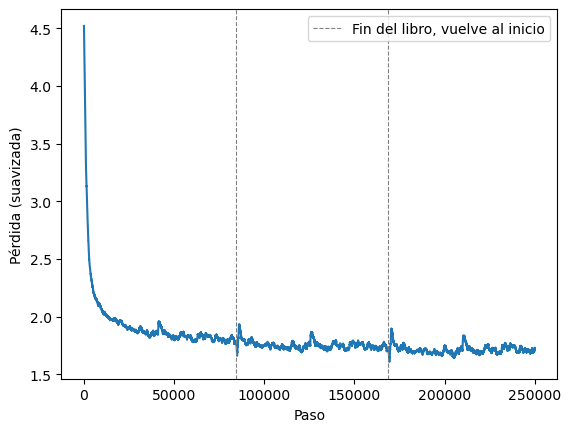

In [14]:
pasos_por_pasada = (len(datos) - l_ventana - 1) // l_ventana + 1

plt.plot(perdidas)
for k in range(1, len(perdidas) // pasos_por_pasada + 1):
  plt.axvline(k * pasos_por_pasada, color='gray', linestyle='--', linewidth=0.8,
              label='Fin del libro, vuelve al inicio' if k == 1 else None)

plt.xlabel('Paso')
plt.ylabel('Pérdida (suavizada)')
plt.legend()
plt.show()

## Generación
Generamos 500 caracteres con el modelo entrenado a partir de un estado inicial de ceros. Como primer carácter de entrada usamos el salto de línea (`'\n'`, índice 0 del vocabulario), de modo que el modelo genera como si empezara un párrafo nuevo. En cada paso muestreamos el siguiente carácter con temperatura $\tau = 0.8$, que concentra un poco la distribución.

In [15]:
h0 = th.zeros(modelo.d_edo, device=modelo.disp)
print(modelo.genera(h0, c2i['\n'], tamgen=500, temp=0.8))

hila de encantamo que, que camo, suces hecho, y que na tenge y molenes te desance; no que te vala de pues andan te he haya a que que no que no tal gennotas, de quido había me ha rayas que fue el pastave
y algún mi neseres que vales de ojas pastorase de quiece no bensanda; por la parecer no quebrás no pues hay, y quien sora las cardad, que no
mos desga que nuesa mano pues tambarlos por abrascadad
que de
no me valo que me ta vaca responderas quiera —dijo Sancho—, que se vergus de soras pues, soy c
